# 12 — Historique long et stress tests

Historique mensuel en EUR depuis 2004, prolongé par des **proxys de même exposition** avant la cotation des ETF PEA (`config/long_history.yaml`) : ces mois sont **synthétiques**. Même moteur que `python main.py stress`. Aucun ordre, aucune modification de la politique.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'config').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.cli.common import _long_universe, _strategy_context
from src.costs import load_fee_model
from src.long_history import load_long_config, load_long_history, synthetic_share
from src.monthly_pipeline import load_config
from src.patrimoine import load_patrimoine_config
from src.policy import load_policy
from src.stress import STRESS_WINDOWS, run_stress, stress_conclusion
from src.taxes import tax_config_from
from src.universe import asset_roles, load_universe

config = load_config(PROJECT_ROOT / 'config' / 'strategy_params.yaml')
policy = load_policy(PROJECT_ROOT / 'config' / 'policy.yaml')
roles = asset_roles(load_universe(PROJECT_ROOT / 'config' / 'assets.yaml'))
long_config = load_long_config(PROJECT_ROOT / 'config' / 'long_history.yaml')
prices, sources = load_long_history(PROJECT_ROOT / 'data' / 'processed' / 'long_history.csv',
                                    PROJECT_ROOT / 'data' / 'processed' / 'long_history_sources.csv')
monthly = _long_universe(prices, roles, long_config)
pd.DataFrame(synthetic_share(sources)).T.loc[monthly.columns]

,start,real_start,synthetic_months,synthetic_share
CW8.PA,2003-12-31,2015-01-31,133,0.487179
PUST.PA,2003-12-31,2015-01-31,133,0.487179
ESE.PA,2003-12-31,2015-01-31,133,0.487179
PAEEM.PA,2003-12-31,2019-04-30,184,0.673993
PCEU.PA,2005-03-31,2019-04-30,169,0.655039
PAASI.PA,2003-12-31,2019-04-30,184,0.673993
OBLI.PA,2008-01-31,2018-12-31,131,0.584821


In [2]:
patrimoine = load_patrimoine_config(PROJECT_ROOT / 'config' / 'patrimoine.yaml')
study = run_stress(monthly, sources, _strategy_context(config, roles, monthly.columns, policy),
                   transaction_cost=config.backtest.transaction_cost,
                   monthly_contribution=float(patrimoine['profil']['versement_mensuel_eur']),
                   horizon_months=policy.horizon_ans * 12, fee_model=load_fee_model(PROJECT_ROOT / 'config' / 'strategy_params.yaml'),
                   taxes=tax_config_from(patrimoine), drawdown_limit=policy.drawdown_max_accepte,
                   followed=policy.strategie_suivie)
table = study['table'].copy()
table['stratégie'] = table['stratégie'].map(study['labels'])
table.pivot(index='stratégie', columns='fenêtre', values='drawdown_max')[[w[0] for w in STRESS_WINDOWS]].style.format('{:.1%}', na_rep='—')

fenêtre,Crise financière 2008-09,Crise de la dette euro 2011,Chine / pétrole 2015-16,T4 2018,Covid 2020,Inflation et taux 2022
stratégie,,,,,,
60/40 CW8.PA / OBLI.PA,—,-8.1%,-8.2%,-6.7%,-12.5%,-14.3%
80/20 CW8.PA / OBLI.PA,—,-11.3%,-10.0%,-9.2%,-15.6%,-13.7%
Buy & Hold CW8.PA,-50.7%,-30.4%,-12.2%,-11.6%,-18.6%,-14.1%
Cœur / satellite (80% CW8.PA + 20% momentum_vt),-44.1%,-25.1%,-11.0%,-11.9%,-16.7%,-12.8%
Dual momentum (actions / obligataire / cash),-30.4%,-19.0%,-11.5%,-15.7%,-10.9%,-18.7%
Inverse volatilité (actions),-49.3%,-22.9%,-14.1%,-10.7%,-16.9%,-16.4%
Momentum + Volatility Targeting,-20.4%,-15.1%,-11.1%,-13.2%,-8.8%,-16.0%
Momentum défensif,-29.6%,-21.5%,-14.9%,-15.7%,-11.0%,-19.6%
Top 3 équipondéré + tendance,-22.1%,-10.3%,-14.6%,-13.1%,-13.6%,-14.9%


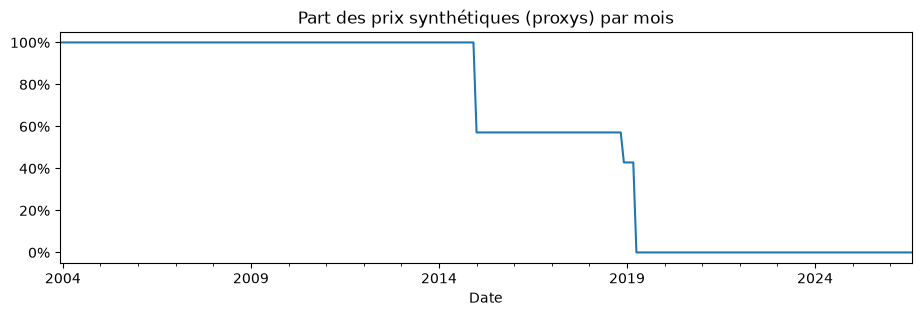

In [3]:
fig, ax = plt.subplots(figsize=(11, 3))
study['synthetic_share'].plot(ax=ax, title='Part des prix synthétiques (proxys) par mois')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.show()

## Versements programmés : distribution des résultats

In [4]:
rows = []
for name, item in study['outcomes'].items():
    rows.append({'stratégie': study['labels'][name], 'net p5': item['final_net']['p5'], 'net p50': item['final_net']['p50'],
                 'net p95': item['final_net']['p95'], 'P(perte)': item['prob_loss'],
                 'P(DD > limite)': item['prob_drawdown_beyond_limit']})
pd.DataFrame(rows).set_index('stratégie').style.format({'net p5': '{:,.0f} €', 'net p50': '{:,.0f} €', 'net p95': '{:,.0f} €',
                                                         'P(perte)': '{:.0%}', 'P(DD > limite)': '{:.0%}'})

,net p5,net p50,net p95,P(perte),P(DD > limite)
stratégie,,,,,
Buy & Hold CW8.PA,"234,688 €","604,176 €","1,481,238 €",1%,88%
Momentum défensif,"361,576 €","985,408 €","2,951,198 €",0%,80%
Momentum + Volatility Targeting,"265,932 €","521,144 €","1,059,692 €",0%,46%
Inverse volatilité (actions),"288,764 €","769,218 €","2,057,976 €",0%,90%
80/20 CW8.PA / OBLI.PA,"262,154 €","520,980 €","1,026,932 €",0%,79%
60/40 CW8.PA / OBLI.PA,"232,271 €","385,782 €","650,797 €",0%,46%
Dual momentum (actions / obligataire / cash),"574,213 €","1,591,321 €","4,714,426 €",0%,79%
Top 3 équipondéré + tendance,"422,224 €","971,872 €","2,326,199 €",0%,45%
Cœur / satellite (80% CW8.PA + 20% momentum_vt),"250,654 €","587,052 €","1,313,547 €",0%,81%


In [5]:
for line in stress_conclusion(study):
    print(line)

- Crise financière 2008-09 : drawdown le plus limité Momentum + Volatility Targeting (-20.4%), le plus profond Buy & Hold CW8.PA (-50.7%).
- Crise de la dette euro 2011 : drawdown le plus limité 60/40 CW8.PA / OBLI.PA (-8.1%), le plus profond Buy & Hold CW8.PA (-30.4%).
- Chine / pétrole 2015-16 : drawdown le plus limité 60/40 CW8.PA / OBLI.PA (-8.2%), le plus profond Momentum défensif (-14.9%).
- T4 2018 : drawdown le plus limité 60/40 CW8.PA / OBLI.PA (-6.7%), le plus profond Momentum défensif (-15.7%).
- Covid 2020 : drawdown le plus limité Momentum + Volatility Targeting (-8.8%), le plus profond Buy & Hold CW8.PA (-18.6%).
- Inflation et taux 2022 : drawdown le plus limité Cœur / satellite (80% CW8.PA + 20% momentum_vt) (-12.8%), le plus profond Momentum défensif (-19.6%).
- Stratégie suivie (momentum_vt) : probabilité simulée de dépasser un drawdown de 25% sur l'horizon = 46%.
- Résultats indicatifs : données partiellement synthétiques, passé non représentatif du futur.


## Limites

- Données majoritairement synthétiques avant 2015-2019 ; proxys en USD convertis en EUR.
- Avant 2009, le proxy MSCI World exclut les dividendes (Buy & Hold sous-estimé).
- Le bootstrap rejoue le passé : il ne prévoit pas de régimes inédits.
- Le choix de la stratégie suivie reste une décision humaine (`config/policy.yaml`).